In [1]:
%load_ext autoreload 
%autoreload 2 

# Degree Centrality & Source and Target Distribution

Computing source and target distributions of the top 10 referenced sections.

## 0. Set Up

In [2]:
# Imports

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from sklearn.preprocessing import normalize


from network_pluralism.access.resolved import to_level
from network_pluralism.access.utils.files import save_matrix, load_indices, load_matrix
from network_pluralism.access.filtered import get_filtered_matrix
from network_pluralism.access.ego import get_ego_matrix
from network_pluralism.access.projected import to_projection
from network_pluralism.access.utils.labels import (
    get_well_written_sections,
    get_well_written_section,
)
from network_pluralism.access.utils.df import return_top_n
from network_pluralism.visualization.boxes import plot_boxes
from network_pluralism.setup.paths import COMPUTATION_PATH, PREPROCESSED_DATA_DECISIONS


In [3]:
# Matplotlib Config


def set_rcParams(**kwargs):
    params = {
        "pdf.fonttype": 42,
        "text.usetex": False,
        "font.family": "serif",
        "text.latex.preamble": r"\usepackage{amssymb}\usepackage{amsmath}",
        "font.size": 16,
        "legend.fontsize": 14,
        "legend.title_fontsize": 16,
        "axes.labelsize": 18,
        "xtick.labelsize": 16,
        "ytick.labelsize": 16,
        "axes.spines.right": False,
        "axes.spines.top": False,
        "legend.columnspacing": 1.0,
        "legend.frameon": False,
        "lines.linewidth": 3,
    }
    for param in kwargs:
        if param in plt.rcParams.keys():
            params[param] = kwargs[param]
    for k, v in params.items():
        plt.rcParams[k] = v


set_rcParams()

In [4]:
EXPORT_PATH = Path('../../figures_and_results/source_and_target')
EXPORT_PATH.mkdir(exist_ok=True, parents=True)

## 2. Computations

In [5]:
# General Set-Up
normalize_method = 'l2'
n = 10

### a)  Absolute Frequency (= Degree Centraliity)

In [6]:
matrix, rows_mapping, col_mapping = to_level(0,1)

Out Matrix of shape (8, 93645)


In [7]:
top_n_cited_norms_df = return_top_n(matrix, rows_mapping, col_mapping, axis=0,top_n=n)
top_n_cited_norms_df

,count
markeng_8,25054.0
gg_3,17785.0
vwgo_132,15521.0
gg_2,12713.0
gg_103,11943.0
fgo_115,9911.0
gg_20,8388.0
bgb_307,7879.0
zpo_563,7872.0
stpo_349,7764.0


In [8]:
top_n_cited_norms_df.to_csv(EXPORT_PATH / f"degree_centrality_top_{n}.csv")

### b)  Source Distribution

In [9]:
top_n_cited_norms = list(top_n_cited_norms_df.index)

In [10]:
matrix_filtered, rows_mapping_filtered, col_mapping_filtered = get_filtered_matrix(
    statutes=top_n_cited_norms, s=1, d=0
)

Out Matrix of shape (8, 93645)


In [11]:
normalized_matrix = normalize(matrix_filtered, norm=normalize_method, axis=0)
row_labels = [k for k, v in sorted(rows_mapping_filtered.items(), key=lambda x: x[1])]
col_labels = [k for k, v in sorted(col_mapping_filtered.items(), key=lambda x: x[1])]
df_matrix_filtered = pd.DataFrame.sparse.from_spmatrix(normalized_matrix, index=row_labels, columns=col_labels)


In [12]:
# prepare data for vizualisation function
df_dict = df_matrix_filtered.to_dict()
data = []

for s in top_n_cited_norms:
    data.append(
        {
            'widths':[1 for i in range(7)],
            'strengths':list(df_dict[s].values())
        }
    )


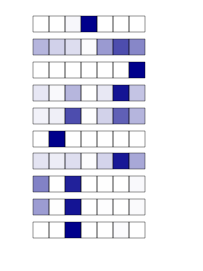

In [13]:
max_width = max([sum(d.get("widths")) for d in data]) - 1

fig, ax = plt.subplots(figsize=(max_width / 2.54, len(data) / 2.54))
ax.set_aspect("equal")
ax.set_ylim(-1, len(data))
ax.set_xlim(-1, max_width + 1)


for i, item in enumerate(data):
    plot_boxes(
        ax=ax,
        y_start=len(data) - i,
        equal_length=True,
        scale_y=0.7,
        uni_color="darkblue",
        align_boxes="left",
        **item,
    )
ax.set_axis_off()

plt.savefig(
    EXPORT_PATH / f"groupbycourt_{normalize_method}_{n}.pdf",
    dpi=600,
    transparent=True,
    bbox_inches="tight",
)

### c) Target Distribution

In [14]:
levels_df = pd.read_parquet(COMPUTATION_PATH / 'levels.parquet')
levels_df.head()

,sem_id,level,levels_below_min,relative_min,levels_below_max,relative_max
0,euvtrg_1,1,0,1.0,0,1.0
1,euvtrg_2,1,0,1.0,0,1.0
2,euvtrg_3,1,1,0.5,1,0.5
3,euvtrg_3_1,2,0,1.0,0,1.0
4,euvtrg_3_2,2,0,1.0,0,1.0


In [15]:
aggregation_matrix, am_rows, am_cols = load_matrix(name=f"statutes_level_{1}")
row_labels = list(am_rows.keys())
col_labels = list(am_cols.keys())

coo = aggregation_matrix.tocoo()
edge_list_df = pd.DataFrame({
    "source": [row_labels[i] for i in coo.row],
    "target": [col_labels[j] for j in coo.col],
    "weight": coo.data
})
edge_list_df

,source,target,weight
0,euvtrg_1,euvtrg_1,1
1,euvtrg_2,euvtrg_2,1
2,euvtrg_3,euvtrg_3_2,1
3,euvtrg_3,euvtrg_3_1,1
4,mstdvdv_2024_1,mstdvdv_2024_1_2,1
...,...,...,...
268567,auslwbentschg_20,auslwbentschg_20_2,1
268568,auslwbentschg_20,auslwbentschg_20_1,1
268569,auslwbentschg_20,auslwbentschg_20_3,1
268570,auslwbentschg_21,auslwbentschg_21,1


In [16]:
chilren_of_top_n_cited_norms = edge_list_df.set_index('source').loc[top_n_cited_norms].target.reset_index()
chilren_of_top_n_cited_norms['order'] = chilren_of_top_n_cited_norms['target'].str.split('_').str[-1].astype(int)
chilren_of_top_n_cited_norms = (
    chilren_of_top_n_cited_norms.sort_values(['source', 'order'])
    .drop(columns='order')
    .reset_index(drop=True)
)
children_dict = chilren_of_top_n_cited_norms.groupby('source')['target'].agg(list).to_dict()
children_dict

{'bgb_307': ['bgb_307_1', 'bgb_307_2', 'bgb_307_3'],
 'fgo_115': ['fgo_115_1', 'fgo_115_2', 'fgo_115_3'],
 'gg_103': ['gg_103_1', 'gg_103_2', 'gg_103_3'],
 'gg_2': ['gg_2_1', 'gg_2_2'],
 'gg_20': ['gg_20_1', 'gg_20_2', 'gg_20_3', 'gg_20_4'],
 'gg_3': ['gg_3_1', 'gg_3_2', 'gg_3_3'],
 'markeng_8': ['markeng_8_1', 'markeng_8_2', 'markeng_8_3', 'markeng_8_4'],
 'stpo_349': ['stpo_349_1',
  'stpo_349_2',
  'stpo_349_3',
  'stpo_349_4',
  'stpo_349_5'],
 'vwgo_132': ['vwgo_132_1', 'vwgo_132_2', 'vwgo_132_3'],
 'zpo_563': ['zpo_563_1', 'zpo_563_2', 'zpo_563_3', 'zpo_563_4']}

In [17]:
occurrences_df = pd.read_pickle(PREPROCESSED_DATA_DECISIONS / 'matched_numerical_ids.pkl')
occurrences_df.head()

,Unnamed: 0,court,panel,decision,paragraph,pos,semantical_id,start,end,item,level,type,UUID
0,0,BPatG,BPatG_25. Senat,25 W (pat) 508/19,25 W (pat) 508/19_15,0,markeng_8_2_1,292.0,308.0,markeng_8_2_1,3,0,42064170535519776492744549313932832938
1,1,BPatG,BPatG_25. Senat,25 W (pat) 508/19,25 W (pat) 508/19_22,0,markeng_8_2_1,37.0,53.0,markeng_8_2_1,3,0,42064170535519776492744549313932832938
2,3,BPatG,BPatG_25. Senat,25 W (pat) 216/09,25 W (pat) 216/09_3,0,markeng_54_2,96.0,114.0,markeng_54_2,2,0,242215549959440275685037571880796361276
3,4,BPatG,BPatG_25. Senat,25 W (pat) 508/19,25 W (pat) 508/19_21,1,markeng_8_2_1,371.0,387.0,markeng_8_2_1,3,0,42064170535519776492744549313932832938
4,5,BPatG,BPatG_25. Senat,25 W (pat) 508/19,25 W (pat) 508/19_21,0,markeng_64_6,9.0,32.0,markeng_64_6,2,0,317653909489634983075549076632237719954


In [18]:
matrix, rows_mapping, col_mapping = get_filtered_matrix(statutes=chilren_of_top_n_cited_norms.target.to_list(),d=0,s=2)

Out Matrix of shape (8, 268552)


In [19]:
data = []
data_parents = []

frequencies = matrix.sum(axis=0).A1
for s  in top_n_cited_norms:
    children = children_dict[s]
    widths = [1 for _ in range(len(children))]
    strengths = [frequencies[col_mapping[c]] for c in children]
    strengths = [occurrences_df.query(f'item=="{c}"').__len__() for c in children]
    
    # Add all direct citations to 
    direct_citation_of_parent = occurrences_df.query(f'item=="{s}"').__len__()
    strengths.append(direct_citation_of_parent)

    strengths_normalized = normalize(np.array(strengths).reshape(1, -1), norm=normalize_method)[0].tolist()
    parent_strength = strengths_normalized.pop(-1)
    data.append({"widths": widths, "strengths": strengths_normalized})
    data_parents.append({"widths": {1}, "strengths": {parent_strength}})


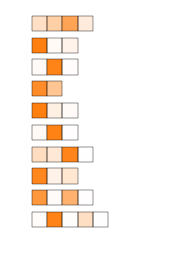

In [20]:
# plotting only the child boxes

max_width = max([sum(d.get("widths")) for d in data]) 

fig, ax = plt.subplots(figsize=(max_width / 2.54, len(data) / 2.54))
ax.set_aspect("equal")
ax.set_ylim(-1, len(data))
ax.set_xlim(-1, max_width + 1)

for i, item in enumerate(data):
    plot_boxes(
        ax=ax,
        y_start=len(data) - i,
        equal_length=True,
        scale_y=0.7,
        align_boxes="left",
        **item,
    )
ax.set_axis_off()
plt.savefig(EXPORT_PATH / f"groupbytarget_{normalize_method}_{n}.pdf", dpi=600, transparent=True, bbox_inches="tight")

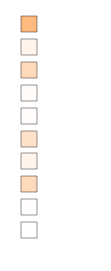

In [21]:
# plotting the parent boxes
max_width = 3

fig, ax = plt.subplots(figsize=(max_width / 2.54, len(data) + 1 / 2.54))
ax.set_aspect("equal")
ax.set_ylim(-1, len(data))
ax.set_xlim(-1, max_width)

for i, item in enumerate(data_parents):
    plot_boxes(
        ax=ax,
        y_start=len(data) - i,
        equal_length=True,
        scale_y=0.7,
        **item,
    )
ax.set_axis_off()
plt.savefig(
    EXPORT_PATH / f"groupbytarget_parents_{normalize_method}_{n}.pdf", dpi=600, transparent=True, bbox_inches="tight"
)